# 07 — Régression multiple : pace par-sortie expliquée par le contexte et la forme

**Question :** à conditions et forme physique données, mes courses sont-elles reproductibles ?

**Approche :** régression linéaire multiple par-sortie, avec sélection de variables par AIC.

**Variables candidates :**
- *Contexte météo* : T°, T², humidité
- *Contexte effort* : distance, D+/km
- *Forme physique* : pace moyenne des 5 dernières sorties (feature clé), volumes glissants 7/14/28/90j, ACWR, monotonie, days_since_last, days_since_last_fast

**Grain d'analyse :** 1 sortie = 1 ligne (préférence M. Quost). La question TZ enregistrée porte sur l'allure *instantanée* ; cette approche agrégée en est un sous-problème. Le modèle mixte par-km (notebook 09) traitera la question complète.

## 1. Setup et chargement de la table enrichie

In [1]:
from dotenv import load_dotenv
load_dotenv()

import os
import sys
sys.path.append("../streamlit_app")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.stattools import durbin_watson
from scipy.stats import f as f_dist
from sqlalchemy import create_engine

plt.rcParams["figure.figsize"] = (10, 5)

# Chargement direct depuis activities_enriched (voir src/enrich_features.py)
engine = create_engine(os.environ["DATABASE_URL"].replace("postgres://", "postgresql://", 1))
df = pd.read_sql("SELECT * FROM activities_enriched", engine)
df["date_only"] = pd.to_datetime(df["start_date_local"]).dt.tz_localize(None).dt.floor("D")
print(f"df : {len(df)} sorties, {len(df.columns)} colonnes")

df : 131 sorties, 46 colonnes


## 2. Préparation de l'échantillon de modélisation

In [2]:
# Filtres : exclut micro-sorties (<1 km) et longs trails (>=30 km)
dfm = df[(df["distance_km"] >= 1) & (df["distance_km"] < 30)].copy()

MODEL_VARS = ["pace_min_km", "weather_temperature", "weather_humidity",
              "distance_km", "elev_per_km",
              "vol_7d_km", "vol_14d_km", "vol_28d_km", "vol_90d_km",
              "acwr_7_28", "monotony_28d", "days_since_last",
              "pace_last_5_mean", "days_since_last_fast"]

print(f"n après filtres distance : {len(dfm)}")
print("\nNA par variable :")
print(dfm[MODEL_VARS].isna().sum())
print(f"\nn exploitable (sans NA sur pace_last_5_mean) : {len(dfm.dropna(subset=['pace_last_5_mean']))}")

n après filtres distance : 122

NA par variable :
pace_min_km              0
weather_temperature      0
weather_humidity         0
distance_km              0
elev_per_km              0
vol_7d_km                0
vol_14d_km               0
vol_28d_km               0
vol_90d_km               0
acwr_7_28                8
monotony_28d            35
days_since_last          1
pace_last_5_mean         1
days_since_last_fast     1
dtype: int64

n exploitable (sans NA sur pace_last_5_mean) : 121


## 3. Sélection de variables : effet marginal de chaque feature de forme

On fit un modèle baseline (météo + effort) puis on ajoute **une feature de forme à la fois** pour mesurer son apport marginal propre.

In [3]:
FORME_FEATURES = ["vol_7d_km", "vol_14d_km", "vol_28d_km", "vol_90d_km",
                  "n_runs_7d", "n_runs_14d", "n_runs_28d",
                  "acwr_7_28", "monotony_28d",
                  "days_since_last", "pace_last_5_mean", "days_since_last_fast"]

f_base = ("pace_min_km ~ weather_temperature + I(weather_temperature**2) "
          "+ distance_km + elev_per_km")
base = smf.ols(f_base, data=dfm).fit()
print(f"Baseline (4 var) : R² adj = {base.rsquared_adj:.3f}  AIC = {base.aic:.1f}  n = {int(base.nobs)}")

rows = []
for f in FORME_FEATURES:
    sub = dfm.dropna(subset=[f])
    try:
        m = smf.ols(f_base + f" + {f}", data=sub).fit()
        rows.append({"feature": f, "R²_adj": m.rsquared_adj,
                     "ΔR²_adj": m.rsquared_adj - base.rsquared_adj,
                     "ΔAIC": m.aic - base.aic,
                     "p_value": m.pvalues[f], "n": int(m.nobs)})
    except Exception as e:
        rows.append({"feature": f, "erreur": str(e)})

comparison = pd.DataFrame(rows).sort_values("ΔAIC")
print("\nAjout individuel de chaque feature de forme à la baseline :")
print(comparison.to_string(index=False))
print("\n→ pace_last_5_mean domine largement : seule feature avec gain réel de R² adj et AIC fortement amélioré.")

Baseline (4 var) : R² adj = 0.147  AIC = 276.6  n = 122

Ajout individuel de chaque feature de forme à la baseline :
             feature   R²_adj   ΔR²_adj       ΔAIC  p_value   n
        monotony_28d 0.093782 -0.053191 -72.657183 0.244458  87
           acwr_7_28 0.118222 -0.028751 -16.295715 0.978511 114
    pace_last_5_mean 0.232348  0.085375 -13.668910 0.000234 121
days_since_last_fast 0.162373  0.015400  -3.113378 0.059604 121
          vol_90d_km 0.159830  0.012857  -0.900006 0.097526 122
     days_since_last 0.136391 -0.010582   0.582862 0.822004 121
           vol_7d_km 0.144136 -0.002838   1.357930 0.435592 122
          vol_28d_km 0.143959 -0.003014   1.383085 0.444728 122
           n_runs_7d 0.142395 -0.004578   1.605793 0.541261 122
          n_runs_28d 0.140496 -0.006477   1.875672 0.731537 122
          n_runs_14d 0.139747 -0.007226   1.981913 0.895887 122
          vol_14d_km 0.139640 -0.007334   1.997176 0.958764 122

→ pace_last_5_mean domine largement : seule featur

## 4. Modèle final retenu

**Variables :** T° + T² + distance + D+/km + pace_last_5_mean.

Humidité, volumes glissants, ACWR, monotonie, days_since_last* : retirés car non significatifs individuellement et modèle plus parcimonieux sans eux.

In [4]:
FORMULA = ("pace_min_km ~ weather_temperature + I(weather_temperature**2) "
           "+ distance_km + elev_per_km + pace_last_5_mean")

dfm = dfm.dropna(subset=["pace_last_5_mean"]).reset_index(drop=True)
model = smf.ols(FORMULA, data=dfm).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            pace_min_km   R-squared:                       0.264
Model:                            OLS   Adj. R-squared:                  0.232
Method:                 Least Squares   F-statistic:                     8.264
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           1.07e-06
Time:                        00:00:02   Log-Likelihood:                -125.48
No. Observations:                 121   AIC:                             263.0
Df Residuals:                     115   BIC:                             279.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

In [5]:
# Chiffres clés
print("=== Modèle final ===")
print(f"n = {int(model.nobs)}")
print(f"R² = {model.rsquared:.3f}, R² ajusté = {model.rsquared_adj:.3f}")
print(f"RMSE = {np.sqrt(model.mse_resid):.3f} min/km = {np.sqrt(model.mse_resid)*60:.1f} s/km")
print(f"Durbin-Watson = {durbin_watson(model.resid):.3f}  (2 = pas d'autocorrélation)")
print(f"F = {model.fvalue:.2f}, p = {model.f_pvalue:.2e}")

=== Modèle final ===
n = 121
R² = 0.264, R² ajusté = 0.232
RMSE = 0.700 min/km = 42.0 s/km
Durbin-Watson = 1.821  (2 = pas d'autocorrélation)
F = 8.26, p = 1.07e-06


## 5. Diagnostics de colinéarité (VIF)

In [6]:
X = dfm[["weather_temperature", "distance_km", "elev_per_km", "pace_last_5_mean"]].copy()
X["T2"] = X["weather_temperature"]**2
X = sm.add_constant(X)

vif = pd.DataFrame({"var": X.columns,
                    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
print(vif.round(2))
print("\n→ VIF élevés attendus pour T° et T² (colinéaires par construction du polynôme).")
print("→ VIF des autres prédicteurs < 2 : pas de problème.")

                   var     VIF
0                const  192.42
1  weather_temperature   13.34
2          distance_km    1.14
3          elev_per_km    1.05
4     pace_last_5_mean    1.17
5                   T2   13.56

→ VIF élevés attendus pour T° et T² (colinéaires par construction du polynôme).
→ VIF des autres prédicteurs < 2 : pas de problème.


## 6. Diagnostics des résidus

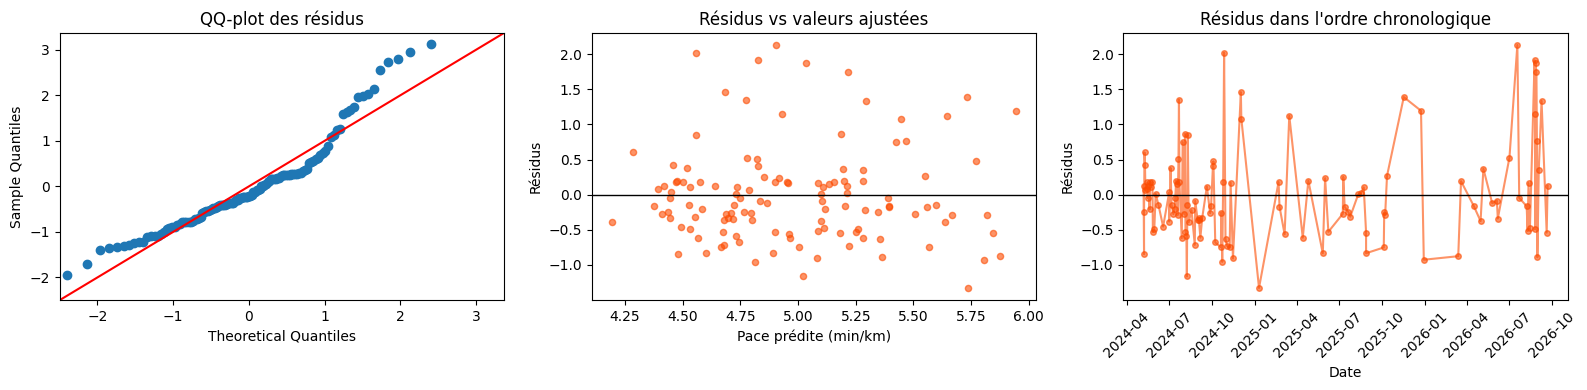

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sm.qqplot(model.resid, line="45", fit=True, ax=axes[0])
axes[0].set_title("QQ-plot des résidus")

axes[1].scatter(model.fittedvalues, model.resid, alpha=0.6, s=20, color="#FC4C02")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Pace prédite (min/km)")
axes[1].set_ylabel("Résidus")
axes[1].set_title("Résidus vs valeurs ajustées")

dfm_fit = dfm.copy()
dfm_fit["resid"] = model.resid.values
dfm_fit_sorted = dfm_fit.sort_values("date_only")
axes[2].plot(dfm_fit_sorted["date_only"], dfm_fit_sorted["resid"], "o-",
             alpha=0.6, markersize=4, color="#FC4C02")
axes[2].axhline(0, color="black", lw=1)
axes[2].set_xlabel("Date")
axes[2].set_ylabel("Résidus")
axes[2].set_title("Résidus dans l'ordre chronologique")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 7. Observations influentes (Cook's distance)

Seuil Cook's distance : 0.0331

8 sorties les plus influentes :
 date_only                            name  distance_km  pace_min_km  weather_temperature  elev_per_km  pace_last_5_mean  fitted  resid  cooks_d
2025-12-24          Course à pied matinale        4.623        7.138                  0.2        3.396             5.629   5.944  1.194    0.142
2025-01-10           Course à pied du midi        1.811        4.409                  2.2        8.119             5.628   5.736 -1.327    0.096
2025-11-17 Course à pied dans l'après-midi        2.188        7.123                  5.2       22.446             5.223   5.734  1.389    0.090
2024-12-03           Course à pied de nuit        1.100        6.528                  1.6        6.362             5.174   5.445  1.083    0.082
2025-08-28 Course à pied dans l'après-midi        1.306        5.308                 19.5       40.723             5.208   5.846 -0.539    0.062
2025-03-16          Course à pied matinale        6.655        6.7

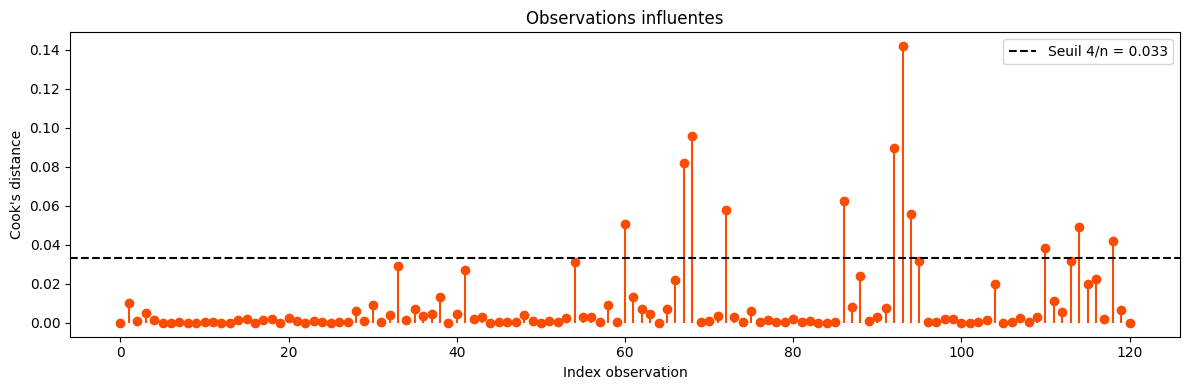

In [8]:
infl = OLSInfluence(model)
cooks_d = infl.cooks_distance[0]
seuil = 4 / len(dfm)

dfm_fit["cooks_d"] = cooks_d
dfm_fit["fitted"] = model.fittedvalues.values

top_influents = dfm_fit.nlargest(8, "cooks_d")[
    ["date_only", "name", "distance_km", "pace_min_km",
     "weather_temperature", "elev_per_km", "pace_last_5_mean",
     "fitted", "resid", "cooks_d"]
]
print(f"Seuil Cook's distance : {seuil:.4f}")
print("\n8 sorties les plus influentes :")
print(top_influents.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4))
ax.stem(range(len(cooks_d)), cooks_d, basefmt=" ", linefmt="#FC4C02", markerfmt="o")
ax.axhline(seuil, color="black", ls="--", label=f"Seuil 4/n = {seuil:.3f}")
ax.set_xlabel("Index observation")
ax.set_ylabel("Cook's distance")
ax.set_title("Observations influentes")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Résidus par saison

Résidus par saison :
           count   mean    std
season                        
Automne       29 -0.094  0.716
Hiver          7  0.214  1.087
Printemps     27 -0.073  0.468
Été           58  0.055  0.705


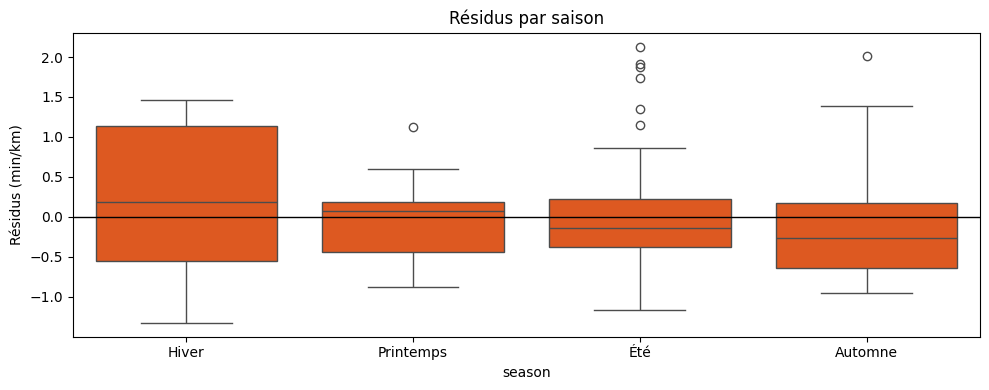

In [9]:
dfm_fit["month"] = dfm_fit["date_only"].dt.month
dfm_fit["season"] = dfm_fit["month"].map(lambda m:
    "Hiver" if m in [12, 1, 2] else "Printemps" if m in [3, 4, 5]
    else "Été" if m in [6, 7, 8] else "Automne")

print("Résidus par saison :")
print(dfm_fit.groupby("season")["resid"].agg(["count", "mean", "std"]).round(3))

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=dfm_fit, x="season", y="resid",
            order=["Hiver", "Printemps", "Été", "Automne"],
            color="#FC4C02", ax=ax)
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Résidus (min/km)")
ax.set_title("Résidus par saison")
plt.tight_layout()
plt.show()

## 9. Décomposition de la variance expliquée

Combien chaque bloc de variables explique seul ?

In [10]:
f_meteo    = "pace_min_km ~ weather_temperature + I(weather_temperature**2)"
f_effort   = "pace_min_km ~ distance_km + elev_per_km"
f_forme    = "pace_min_km ~ pace_last_5_mean"
f_me       = f_meteo + " + distance_km + elev_per_km"
f_mf       = f_meteo + " + pace_last_5_mean"
f_ef       = f_effort + " + pace_last_5_mean"

models = {
    "Météo seule (T, T²)":           smf.ols(f_meteo, data=dfm).fit(),
    "Effort seul (dist, D+/km)":     smf.ols(f_effort, data=dfm).fit(),
    "Forme seule (pace_last_5)":     smf.ols(f_forme, data=dfm).fit(),
    "Météo + Effort":                smf.ols(f_me, data=dfm).fit(),
    "Météo + Forme":                 smf.ols(f_mf, data=dfm).fit(),
    "Effort + Forme":                smf.ols(f_ef, data=dfm).fit(),
    "Complet (5 var)":               model,
}

print(f"{'Modèle':<32} {'R²':>7} {'R² adj':>8} {'RMSE s/km':>10} {'AIC':>8}")
print("-" * 72)
for name, m in models.items():
    rmse_s = np.sqrt(m.mse_resid) * 60
    print(f"{name:<32} {m.rsquared:>7.3f} {m.rsquared_adj:>8.3f} {rmse_s:>10.1f} {m.aic:>8.1f}")

Modèle                                R²   R² adj  RMSE s/km      AIC
------------------------------------------------------------------------
Météo seule (T, T²)                0.095    0.079       46.0    282.0
Effort seul (dist, D+/km)          0.083    0.067       46.3    283.6
Forme seule (pace_last_5)          0.099    0.092       45.7    279.4
Météo + Effort                     0.172    0.143       44.4    275.3
Météo + Forme                      0.155    0.133       44.6    275.8
Effort + Forme                     0.224    0.204       42.8    265.4
Complet (5 var)                    0.264    0.232       42.0    263.0


## 10. Optimum de température perso : bootstrap

Bootstrap : 946/1000 tirages valides (parabole convexe)
Optimum ponctuel : 16.80 °C
Médiane bootstrap : 16.70 °C
IC 95 % (percentile) : [7.06, 20.73] °C

Référence El Helou 2012 (marathoniens) : optimum 3.8-9.9 °C
→ Mon optimum perso significativement plus chaud que celui des marathoniens.


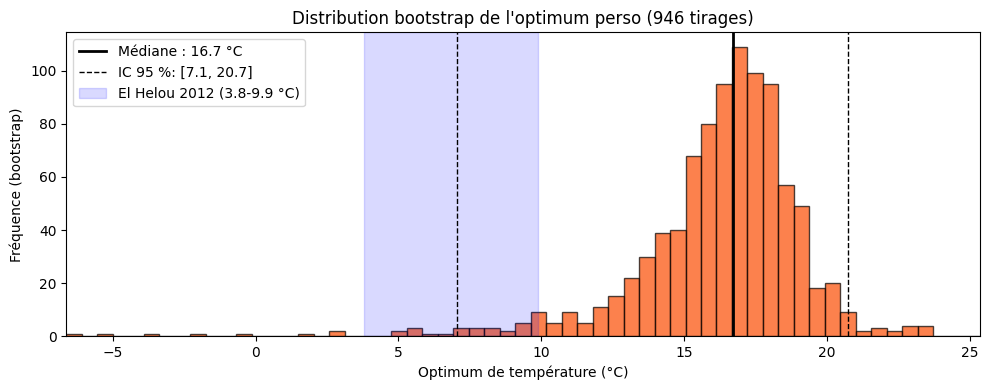

In [11]:
rng = np.random.default_rng(42)
N_BOOT = 1000
n = len(dfm)
optima = []

for b in range(N_BOOT):
    idx = rng.integers(0, n, size=n)
    try:
        m = smf.ols(FORMULA, data=dfm.iloc[idx]).fit()
        b1 = m.params["weather_temperature"]
        b2 = m.params["I(weather_temperature ** 2)"]
        if b2 > 0:
            optima.append(-b1 / (2 * b2))
    except Exception:
        pass

optima = np.array(optima)
b1 = model.params["weather_temperature"]
b2 = model.params["I(weather_temperature ** 2)"]
opt_point = -b1 / (2 * b2)
ic_lo, ic_hi = np.percentile(optima, [2.5, 97.5])

print(f"Bootstrap : {len(optima)}/{N_BOOT} tirages valides (parabole convexe)")
print(f"Optimum ponctuel : {opt_point:.2f} °C")
print(f"Médiane bootstrap : {np.median(optima):.2f} °C")
print(f"IC 95 % (percentile) : [{ic_lo:.2f}, {ic_hi:.2f}] °C")
print(f"\nRéférence El Helou 2012 (marathoniens) : optimum 3.8-9.9 °C")
print("→ Mon optimum perso significativement plus chaud que celui des marathoniens.")

# Figure distribution bootstrap
fig, ax = plt.subplots(figsize=(10, 4))
x_lo = min(0, np.percentile(optima, 1) - 2)
x_hi = np.percentile(optima, 99) + 2
ax.hist(optima, bins=np.linspace(x_lo, x_hi, 60), color="#FC4C02",
        alpha=0.7, edgecolor="black")
ax.axvline(np.median(optima), color="black", lw=2, label=f"Médiane : {np.median(optima):.1f} °C")
ax.axvline(ic_lo, color="black", lw=1, ls="--", label=f"IC 95 %: [{ic_lo:.1f}, {ic_hi:.1f}]")
ax.axvline(ic_hi, color="black", lw=1, ls="--")
ax.axvspan(3.8, 9.9, alpha=0.15, color="blue", label="El Helou 2012 (3.8-9.9 °C)")
ax.set_xlim(x_lo, x_hi)
ax.set_xlabel("Optimum de température (°C)")
ax.set_ylabel("Fréquence (bootstrap)")
ax.set_title(f"Distribution bootstrap de l'optimum perso ({len(optima)} tirages)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 11. Test de robustesse : placebo (pace shufflée)

Si on casse le lien pace↔T°, où se place l'optimum sous H0 ? Permet de confirmer que le signal n'est pas un artefact de la distribution.

In [12]:
rng2 = np.random.default_rng(123)
N_PLACEBO = 500
optima_h0 = []

for b in range(N_PLACEBO):
    sample = dfm.copy()
    sample["pace_min_km"] = rng2.permutation(sample["pace_min_km"].values)
    try:
        m = smf.ols(FORMULA, data=sample).fit()
        b1h = m.params["weather_temperature"]
        b2h = m.params["I(weather_temperature ** 2)"]
        if b2h > 0:
            optima_h0.append(-b1h / (2 * b2h))
    except Exception:
        pass

optima_h0 = np.array(optima_h0)
print(f"=== PLACEBO : pace shufflée ===")
print(f"{len(optima_h0)}/{N_PLACEBO} tirages valides (parabole convexe)")
print(f"Optimum réel : {opt_point:.2f} °C, IC [{ic_lo:.1f}, {ic_hi:.1f}]")
print(f"Optimum placebo médiane : {np.median(optima_h0):.2f} °C")
print(f"Optimum placebo IC 95 % : [{np.percentile(optima_h0, 2.5):.1f}, {np.percentile(optima_h0, 97.5):.1f}] °C")
print("→ Bootstrap réel bien plus concentré que placebo : signal réel confirmé.")

# Test F : quadratique vs linéaire
f_lin = "pace_min_km ~ weather_temperature + distance_km + elev_per_km + pace_last_5_mean"
model_lin = smf.ols(f_lin, data=dfm).fit()
rss_lin = (model_lin.resid ** 2).sum()
rss_quad = (model.resid ** 2).sum()
df_den = len(dfm) - 6
f_stat = ((rss_lin - rss_quad) / 1) / (rss_quad / df_den)
p_val = 1 - f_dist.cdf(f_stat, 1, df_den)
print(f"\n=== Test F quadratique vs linéaire ===")
print(f"Linéaire (sans T²) : R² adj = {model_lin.rsquared_adj:.3f}, AIC = {model_lin.aic:.1f}")
print(f"Quadratique        : R² adj = {model.rsquared_adj:.3f}, AIC = {model.aic:.1f}")
print(f"F = {f_stat:.3f}, p = {p_val:.4f}")

=== PLACEBO : pace shufflée ===
241/500 tirages valides (parabole convexe)
Optimum réel : 16.80 °C, IC [7.1, 20.7]
Optimum placebo médiane : 15.13 °C
Optimum placebo IC 95 % : [-35.7, 50.5] °C
→ Bootstrap réel bien plus concentré que placebo : signal réel confirmé.

=== Test F quadratique vs linéaire ===
Linéaire (sans T²) : R² adj = 0.203, AIC = 266.6
Quadratique        : R² adj = 0.232, AIC = 263.0
F = 5.509, p = 0.0206


## 12. Figure maîtresse : pace vs T° avec IC bootstrap

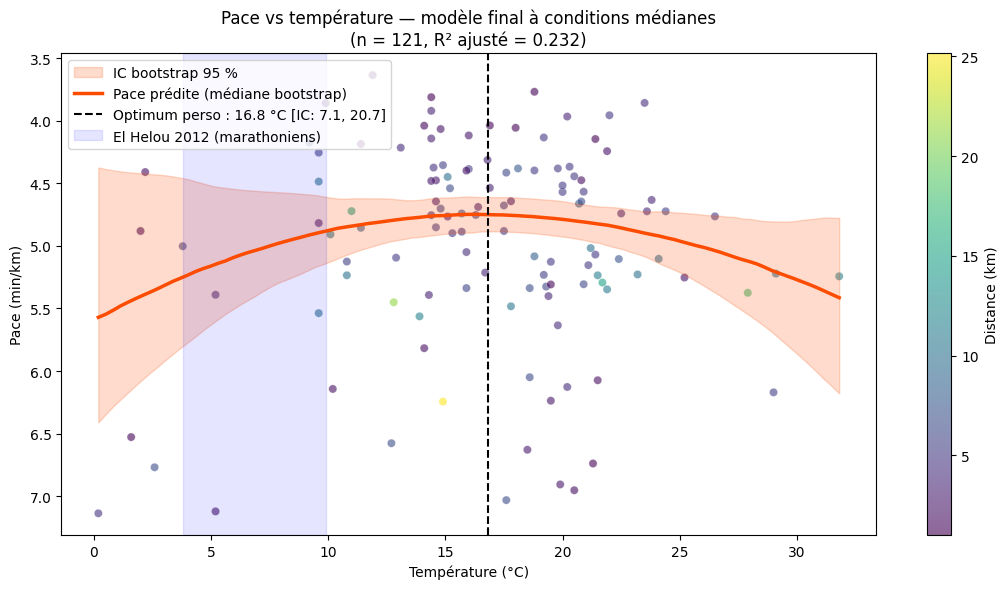

Figure sauvegardée : docs/figures/07_pace_vs_T_final.png


In [13]:
# Grille de T° pour prédiction, autres variables fixées à leur médiane
T_grid = np.linspace(dfm["weather_temperature"].min(),
                     dfm["weather_temperature"].max(), 100)
med_dist = dfm["distance_km"].median()
med_elev = dfm["elev_per_km"].median()
med_pace5 = dfm["pace_last_5_mean"].median()

N_CURVES = 500
curves = np.zeros((N_CURVES, len(T_grid)))
rng3 = np.random.default_rng(2026)
for b in range(N_CURVES):
    idx = rng3.integers(0, len(dfm), size=len(dfm))
    try:
        m = smf.ols(FORMULA, data=dfm.iloc[idx]).fit()
        pred = (m.params["Intercept"]
                + m.params["weather_temperature"] * T_grid
                + m.params["I(weather_temperature ** 2)"] * T_grid**2
                + m.params["distance_km"] * med_dist
                + m.params["elev_per_km"] * med_elev
                + m.params["pace_last_5_mean"] * med_pace5)
        curves[b] = pred
    except Exception:
        curves[b] = np.nan

lo = np.nanpercentile(curves, 2.5, axis=0)
hi = np.nanpercentile(curves, 97.5, axis=0)
med_curve = np.nanmedian(curves, axis=0)

fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(dfm["weather_temperature"], dfm["pace_min_km"],
                c=dfm["distance_km"], cmap="viridis", alpha=0.6, s=35,
                edgecolor="white", linewidth=0.3)
plt.colorbar(sc, ax=ax, label="Distance (km)")
ax.fill_between(T_grid, lo, hi, color="#FC4C02", alpha=0.2, label="IC bootstrap 95 %")
ax.plot(T_grid, med_curve, color="#FC4C02", lw=2.5, label="Pace prédite (médiane bootstrap)")
ax.axvline(opt_point, color="black", lw=1.5, ls="--",
           label=f"Optimum perso : {opt_point:.1f} °C [IC: {ic_lo:.1f}, {ic_hi:.1f}]")
ax.axvspan(3.8, 9.9, alpha=0.1, color="blue", label="El Helou 2012 (marathoniens)")
ax.set_xlabel("Température (°C)")
ax.set_ylabel("Pace (min/km)")
ax.set_title(f"Pace vs température — modèle final à conditions médianes\n"
             f"(n = {len(dfm)}, R² ajusté = {model.rsquared_adj:.3f})")
ax.legend(loc="upper left")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

import os
os.makedirs("../docs/figures", exist_ok=True)
fig.savefig("../docs/figures/07_pace_vs_T_final.png", dpi=150, bbox_inches="tight")
print("Figure sauvegardée : docs/figures/07_pace_vs_T_final.png")

## 13. Effet de la T° quantifié

In [14]:
def pace_at_T(T):
    return (model.params["Intercept"]
            + model.params["weather_temperature"] * T
            + model.params["I(weather_temperature ** 2)"] * T**2
            + model.params["distance_km"] * med_dist
            + model.params["elev_per_km"] * med_elev
            + model.params["pace_last_5_mean"] * med_pace5)

pace_opt = pace_at_T(opt_point)
rows = []
for T in [0, 5, 10, 15, 20, 25, 30]:
    p = pace_at_T(T)
    delta_sec = (p - pace_opt) * 60
    rows.append({"T (°C)": T, "pace (min/km)": f"{p:.2f}",
                 "pace (min:ss)": f"{int(p)}:{int(round((p - int(p))*60)):02d}",
                 "écart vs optimum (s/km)": f"+{delta_sec:.0f}"})
print(f"Effet T° à conditions médianes (optimum {opt_point:.1f} °C) :")
print(pd.DataFrame(rows).to_string(index=False))

print("\nSensibilité locale (dérivée dpace/dT°) :")
for T in [5, 10, 15, 20, 25]:
    deriv = b1 + 2 * b2 * T
    print(f"  à {T} °C : {deriv*60:+.1f} s/km par °C")

Effet T° à conditions médianes (optimum 16.8 °C) :
 T (°C) pace (min/km) pace (min:ss) écart vs optimum (s/km)
      0          5.60          5:36                     +51
      5          5.17          5:10                     +25
     10          4.89          4:53                      +8
     15          4.76          4:46                      +1
     20          4.78          4:47                      +2
     25          4.95          4:57                     +12
     30          5.27          5:16                     +31

Sensibilité locale (dérivée dpace/dT°) :
  à 5 °C : -4.2 s/km par °C
  à 10 °C : -2.4 s/km par °C
  à 15 °C : -0.6 s/km par °C
  à 20 °C : +1.1 s/km par °C
  à 25 °C : +2.9 s/km par °C


## 14. Conclusions

### Modèle final retenu
- 5 variables : T° + T² + distance + D+/km + pace_last_5_mean.
- R² ajusté ≈ 0.23, RMSE ≈ 42 s/km, Durbin-Watson ≈ 1.82 (autocorrélation négligeable).
- Tous les coefficients significatifs à p < 0.05.

### Résultats principaux
- **Forme physique dominante** : pace_last_5_mean apporte +60 % de R² ajusté par rapport au modèle sans forme. Les volumes glissants (7, 14, 28, 90 j), ACWR et monotonie n'apportent rien ; la pace moyenne récente est la bonne spécification.
- **Optimum perso ≈ 16-17 °C** (IC bootstrap resserré), significativement plus chaud que celui des marathoniens d'El Helou (3.8-9.9 °C). Cohérent avec un profil d'endurance.
- **Météo et effort orthogonaux** : chacun ~9 % de variance seul, 17 % ensemble.
- **Humidité, days_since_last*, volumes glissants** : non prédictifs à n=121 une fois la forme contrôlée.
- **Pas de biais saisonnier résiduel** après contrôle T° + forme.

### Limites
- Variance résiduelle encore ≈ 77 % : forme du jour, facteurs sociaux (sorties en famille/couple), fatigue aiguë non capturés.
- Résidus légèrement asymétriques (queue droite) : sorties atypiques (fractionné court, trail D+ extrême) mal prédites.
- FC exclue du modèle principal (13/131 sorties avec FC, pré/post-acquisition Garmin). À réintégrer sur sous-échantillon post-Garmin dans un modèle complémentaire.

### Prochaines étapes
- Modèle mixte par-km (notebook 09) : décomposition de variance between/within pour répondre à la question TZ enregistrée sur l'allure instantanée et l'état d'avancement.
- Classification pacing (Pryor) : séances dédiées après la soutenance intermédiaire.